# 01 — Exploratory Data Analysis of the SBS96 cohorts

This notebook explores the three mutational catalogues in `data/` that feed the NMF + Wasserstein (OT) signature work:

| Cohort | Catalogue | Metadata | Unit of observation |
|---|---|---|---|
| **PCAWG WGS** | `PCAWG_WGS_SBS96_catalog.csv` | `PCAWG_WGS_sample_metadata.csv`, `PCAWG_consortium_sample_sheet.csv` | tumour genome |
| **TCGA WES** | `TCGA_WES_SBS96_catalog.csv` | `TCGA_WES_sample_metadata.csv` | tumour exome |
| **Kucab 2019** | `Kucab2019_SBS96_subclone_catalogue.csv` | `Kucab2019_treatment_metadata.csv` | iPSC subclone exposed to a mutagen |

All catalogues are 96 × N count matrices (rows = trinucleotide-context single-base substitutions, columns = samples).

**Questions addressed**
1. Are the files consistent (shape, channel order, IDs, counts vs. metadata)?
2. What is in each cohort (cancer types / treatments, sample types, QC flags)?
3. How are mutation burdens distributed, and how sparse are the matrices? (Important for NMF with a KL/OT loss.)
4. What do the average spectra look like per cohort, per cancer type and per treatment?
5. How do the cohorts relate to each other in profile space?

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
sns.set_theme(style="ticks", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

# Resolve data/ whether the notebook is run from the repo root or a subfolder
DATA = next(p / "data" for p in [Path.cwd(), *Path.cwd().parents] if (p / "data").is_dir())

COHORTS = ["PCAWG_WGS", "TCGA_WES", "Kucab2019"]
COHORT_COLORS = {"PCAWG_WGS": "#2a78d6", "TCGA_WES": "#eb6834", "Kucab2019": "#1baf7a"}

# Standard COSMIC colours for the six substitution classes
SUBS = ["C>A", "C>G", "C>T", "T>A", "T>C", "T>G"]
SUB_COLORS = dict(zip(SUBS, ["#1ebff0", "#050708", "#e62725", "#cbcacb", "#a1cf64", "#edc8c5"]))
DATA

PosixPath('/Users/hieunguyen/src/nmf_ot_mutsig/data')

## 1. Load data and basic integrity checks

In [2]:
cat = {
    "PCAWG_WGS": pd.read_csv(DATA / "PCAWG_WGS_SBS96_catalog.csv", index_col=0),
    "TCGA_WES": pd.read_csv(DATA / "TCGA_WES_SBS96_catalog.csv", index_col=0),
    "Kucab2019": pd.read_csv(DATA / "Kucab2019_SBS96_subclone_catalogue.csv", index_col=0),
}
meta_pcawg = pd.read_csv(DATA / "PCAWG_WGS_sample_metadata.csv")
meta_tcga = pd.read_csv(DATA / "TCGA_WES_sample_metadata.csv")
meta_kucab = pd.read_csv(DATA / "Kucab2019_treatment_metadata.csv")
pcawg_sheet = pd.read_csv(DATA / "PCAWG_consortium_sample_sheet.csv")

pd.DataFrame({
    name: {
        "channels": X.shape[0],
        "samples": X.shape[1],
        "dtype": str(X.dtypes.unique().tolist()),
        "NaNs": int(X.isna().sum().sum()),
        "negative entries": int((X < 0).sum().sum()),
        "non-integer entries": int((X % 1 != 0).sum().sum()),
        "duplicate sample IDs": int(X.columns.duplicated().sum()),
        "total SBS": int(X.values.sum()),
    }
    for name, X in cat.items()
}).T

,channels,samples,dtype,NaNs,negative entries,non-integer entries,duplicate sample IDs,total SBS
PCAWG_WGS,96,2780,[dtype('int64')],0,0,0,0,48276930
TCGA_WES,96,9493,[dtype('int64')],0,0,0,0,2972987
Kucab2019,96,324,[dtype('int64')],0,0,0,0,172480


### 1.1 Channel order

The 96 channels should be identical (same order) across catalogues, otherwise any joint factorisation or ground-cost matrix will be silently misaligned.

In [3]:
ref_index = cat["PCAWG_WGS"].index
for name, X in cat.items():
    print(f"{name:10s} same channels: {set(X.index) == set(ref_index)}   same order: {X.index.equals(ref_index)}")

# Parse channel names: 'A[C>A]G' -> 5' base, substitution, 3' base
channels = pd.DataFrame({"channel": ref_index})
channels["sub"] = channels.channel.str[2:5]
channels["five"] = channels.channel.str[0]
channels["three"] = channels.channel.str[-1]
print(channels["sub"].value_counts().reindex(SUBS).to_dict())

# Canonical COSMIC ordering: by substitution, then 5' base, then 3' base
channels["sub_rank"] = channels["sub"].map({s: i for i, s in enumerate(SUBS)})
canonical = channels.sort_values(["sub_rank", "five", "three"]).channel
print("Catalogue already in canonical COSMIC order:", ref_index.equals(pd.Index(canonical)))

PCAWG_WGS  same channels: True   same order: True
TCGA_WES   same channels: True   same order: True
Kucab2019  same channels: True   same order: True
{'C>A': 16, 'C>G': 16, 'C>T': 16, 'T>A': 16, 'T>C': 16, 'T>G': 16}
Catalogue already in canonical COSMIC order: True


In [4]:
# Use a single, canonical channel order everywhere below
CHANNELS = pd.Index(canonical)
cat = {k: v.loc[CHANNELS] for k, v in cat.items()}
SUB_OF = channels.set_index("channel").loc[CHANNELS, "sub"].values

### 1.2 Linking catalogues to metadata

In [5]:
# PCAWG / TCGA: column names are '<cancer_type>::<specimen>' and match metadata.sample_id
for name, meta in [("PCAWG_WGS", meta_pcawg), ("TCGA_WES", meta_tcga)]:
    X = cat[name]
    m = meta.set_index("sample_id")
    in_both = X.columns.intersection(m.index)
    burden_match = (X[in_both].sum() == m.loc[in_both, "total_SBS"]).mean()
    print(f"{name}: catalogue={X.shape[1]}, metadata={len(m)}, matched={len(in_both)}, "
          f"total_SBS agrees with column sums for {burden_match:.1%}")
    # cancer type prefix in the column name should agree with metadata
    prefix = X.columns.str.split("::").str[0]
    print(f"   column prefix == metadata cancer_type: {(prefix == m.loc[X.columns, 'cancer_type'].values).mean():.1%}")

PCAWG_WGS: catalogue=2780, metadata=2780, matched=2780, total_SBS agrees with column sums for 100.0%
   column prefix == metadata cancer_type: 100.0%
TCGA_WES: catalogue=9493, metadata=9493, matched=9493, total_SBS agrees with column sums for 100.0%
   column prefix == metadata cancer_type: 100.0%


In [6]:
# Kucab: columns are '<Sample.Name>_s<k>' (subclone k of a treated/untreated parental sample)
kucab_cols = pd.DataFrame({"subclone": cat["Kucab2019"].columns})
kucab_cols["Sample.Name"] = kucab_cols.subclone.str.rsplit("_s", n=1).str[0]
kucab_cols = kucab_cols.merge(meta_kucab, on="Sample.Name", how="left")

unannotated = sorted(kucab_cols.loc[kucab_cols.Compound.isna(), "Sample.Name"].unique())
print(f"Kucab subclones: {len(kucab_cols)} from {kucab_cols['Sample.Name'].nunique()} parental samples")
print(f"Metadata rows: {len(meta_kucab)}; all present in catalogue: {meta_kucab['Sample.Name'].isin(kucab_cols['Sample.Name']).all()}")
print(f"{len(unannotated)} parental samples ({kucab_cols.Compound.isna().sum()} subclones) have no treatment metadata:")
print(unannotated)

Kucab subclones: 324 from 128 parental samples
Metadata rows: 113; all present in catalogue: True
15 parental samples (35 subclones) have no treatment metadata:
['MSM0.1', 'MSM0.118', 'MSM0.119', 'MSM0.120', 'MSM0.127', 'MSM0.128', 'MSM0.129', 'MSM0.131', 'MSM0.37', 'MSM0.4', 'MSM0.45', 'MSM0.6', 'MSM0.8', 'MSM0.86', 'MSM0.9']


The parental samples without a metadata row are most likely the **untreated controls** of the Kucab et al. (2019) design (the metadata table only lists exposures). They are labelled `Unannotated (control?)` below — confirm against the paper's supplementary table before using them as a background.

In [7]:
kucab_cols["Group"] = kucab_cols["Group"].fillna("Unannotated (control?)")
kucab_cols["Treatment"] = kucab_cols["Treatment"].fillna("Unannotated (control?)")
kucab_cols["group_label"] = kucab_cols["Group"].str.replace(r"^[a-z]_", "", regex=True)
kucab_cols["total_SBS"] = cat["Kucab2019"].sum().values
kucab_cols = kucab_cols.set_index("subclone")

## 2. Cohort composition

### 2.1 PCAWG WGS

2780 samples, 37 cancer types


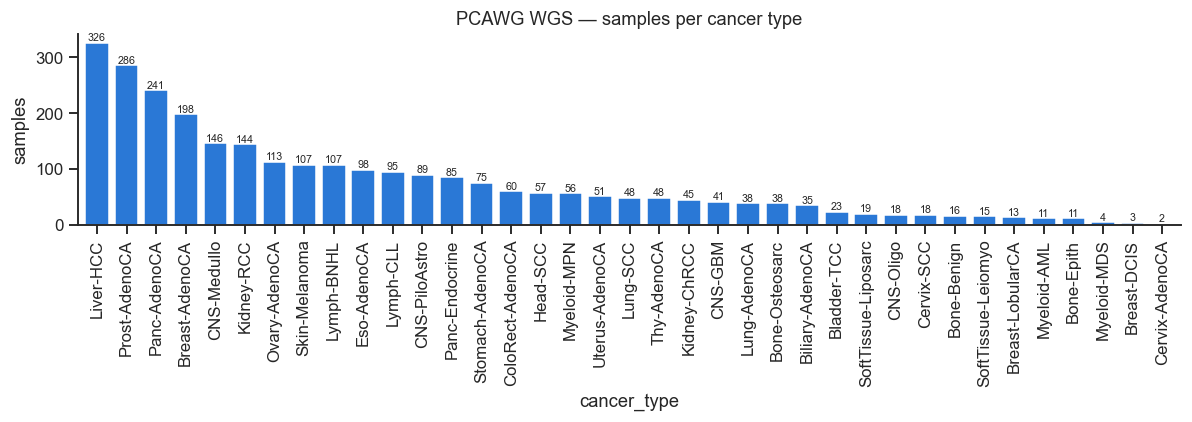

In [8]:
ct_pcawg = meta_pcawg.cancer_type.value_counts()
print(f"{meta_pcawg.shape[0]} samples, {ct_pcawg.size} cancer types")

fig, ax = plt.subplots(figsize=(11, 4))
ct_pcawg.plot.bar(ax=ax, color=COHORT_COLORS["PCAWG_WGS"], width=0.8)
ax.set(ylabel="samples", title="PCAWG WGS — samples per cancer type")
for i, v in enumerate(ct_pcawg.values):
    ax.text(i, v, str(v), ha="center", va="bottom", fontsize=7)
plt.tight_layout()

#### Linking to the PCAWG consortium sample sheet

`specimen_or_barcode` in the catalogue metadata is an ICGC specimen ID. Joining it to the consortium sheet gives the donor, the specimen type and the donor's white/gray/excluded QC status.

In [9]:
wgs_sheet = pcawg_sheet.query("library_strategy == 'WGS'").drop_duplicates("icgc_specimen_id")
pcawg = meta_pcawg.merge(
    wgs_sheet[["icgc_specimen_id", "icgc_donor_id", "dcc_project_code", "dcc_specimen_type", "donor_wgs_exclusion_white_gray"]],
    left_on="specimen_or_barcode", right_on="icgc_specimen_id", how="left",
)
print(f"Matched to sample sheet: {pcawg.icgc_donor_id.notna().sum()} / {len(pcawg)}")
print("Unmatched:", pcawg.loc[pcawg.icgc_donor_id.isna(), "sample_id"].tolist())

donor_counts = pcawg.icgc_donor_id.value_counts()
print(f"Unique donors: {donor_counts.size};  donors with >1 sample in catalogue: {(donor_counts > 1).sum()}")

display(pcawg.donor_wgs_exclusion_white_gray.value_counts(dropna=False).rename("QC status").to_frame())
display(pcawg.dcc_specimen_type.value_counts(dropna=False).rename("specimen type").to_frame())

Matched to sample sheet: 2779 / 2780
Unmatched: ['Myeloid-MPN::SP116883']
Unique donors: 2659;  donors with >1 sample in catalogue: 62


,QC status
donor_wgs_exclusion_white_gray,
Whitelist,2703
Graylist,75
Excluded,1
NaN,1


,specimen type
dcc_specimen_type,
Primary tumour - solid tissue,2205
Primary tumour - blood derived (peripheral blood),146
Primary tumour - other,135
Primary tumour - lymph node,96
Metastatic tumour - metastasis to distant location,48
Metastatic tumour - metastasis local to lymph node,38
Metastatic tumour - NOS,37
Primary tumour - blood derived (bone marrow),23
Recurrent tumour - solid tissue,20


### 2.2 TCGA WES

9493 samples, 32 cancer types, 9455 patients


,samples
tcga_sample_type_code,
01 Primary solid tumour,9003
06 Metastatic,325
03 Primary blood cancer,139
02 Recurrent solid tumour,16
05 Additional new primary,10


Patients with >1 sample: 37 (75 samples)


,sample_id,cancer_type,specimen_or_barcode,cohort,total_SBS,tcga_patient,tcga_sample_type_code
2937,CNS-GBM::TCGA-06-0152-01A-02D-1492-08,CNS-GBM,TCGA-06-0152-01A-02D-1492-08,TCGA_WES,76,TCGA-06-0152,1
2938,CNS-GBM::TCGA-06-0152-02A-01D-2280-08,CNS-GBM,TCGA-06-0152-02A-01D-2280-08,TCGA_WES,85,TCGA-06-0152,2
3134,CNS-GBM::TCGA-19-4065-01A-01D-2280-08,CNS-GBM,TCGA-19-4065-01A-01D-2280-08,TCGA_WES,63,TCGA-19-4065,1
3135,CNS-GBM::TCGA-19-4065-02A-11D-2280-08,CNS-GBM,TCGA-19-4065-02A-11D-2280-08,TCGA_WES,124,TCGA-19-4065,2
8161,Testis-Ca::TCGA-2G-AAGI-01A-11D-A42Y-10,Testis-Ca,TCGA-2G-AAGI-01A-11D-A42Y-10,TCGA_WES,15,TCGA-2G-AAGI,1
8162,Testis-Ca::TCGA-2G-AAGI-05A-11D-A42Y-10,Testis-Ca,TCGA-2G-AAGI-05A-11D-A42Y-10,TCGA_WES,28,TCGA-2G-AAGI,5
8174,Testis-Ca::TCGA-2G-AAGY-01A-11D-A42Y-10,Testis-Ca,TCGA-2G-AAGY-01A-11D-A42Y-10,TCGA_WES,17,TCGA-2G-AAGY,1
8175,Testis-Ca::TCGA-2G-AAGY-05A-11D-A42Y-10,Testis-Ca,TCGA-2G-AAGY-05A-11D-A42Y-10,TCGA_WES,12,TCGA-2G-AAGY,5
8187,Testis-Ca::TCGA-2G-AAHP-01A-12D-A42Y-10,Testis-Ca,TCGA-2G-AAHP-01A-12D-A42Y-10,TCGA_WES,11,TCGA-2G-AAHP,1
8188,Testis-Ca::TCGA-2G-AAHP-05A-11D-A42Y-10,Testis-Ca,TCGA-2G-AAHP-05A-11D-A42Y-10,TCGA_WES,26,TCGA-2G-AAHP,5


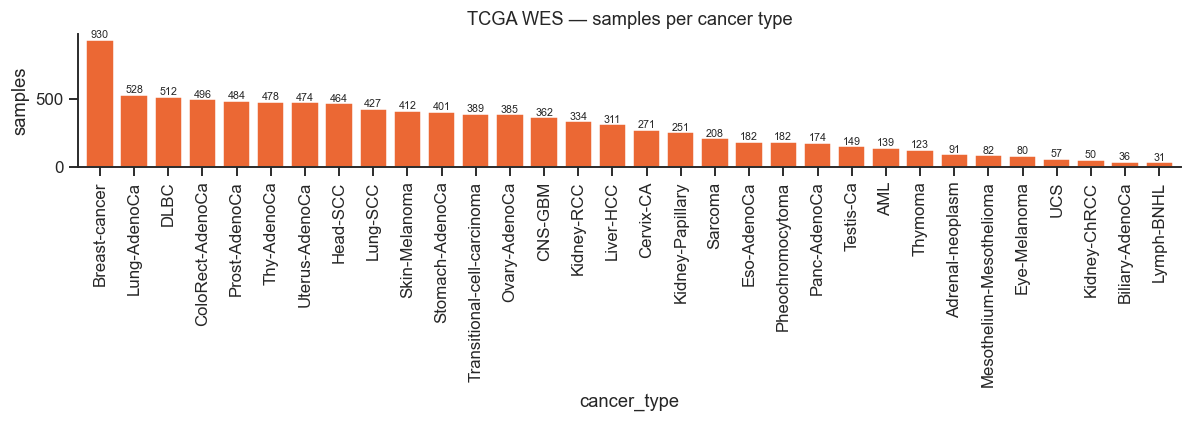

In [10]:
ct_tcga = meta_tcga.cancer_type.value_counts()
print(f"{meta_tcga.shape[0]} samples, {ct_tcga.size} cancer types, {meta_tcga.tcga_patient.nunique()} patients")

# TCGA sample-type codes: 01 primary solid, 02 recurrent solid, 03 primary blood cancer, 05 additional primary, 06 metastatic
code_names = {1: "01 Primary solid tumour", 2: "02 Recurrent solid tumour", 3: "03 Primary blood cancer",
              5: "05 Additional new primary", 6: "06 Metastatic"}
display(meta_tcga.tcga_sample_type_code.map(code_names).value_counts().rename("samples").to_frame())

multi = meta_tcga[meta_tcga.tcga_patient.duplicated(keep=False)].sort_values("tcga_patient")
print(f"Patients with >1 sample: {multi.tcga_patient.nunique()} ({len(multi)} samples)")
display(multi.head(10))

fig, ax = plt.subplots(figsize=(11, 4))
ct_tcga.plot.bar(ax=ax, color=COHORT_COLORS["TCGA_WES"], width=0.8)
ax.set(ylabel="samples", title="TCGA WES — samples per cancer type")
for i, v in enumerate(ct_tcga.values):
    ax.text(i, v, str(v), ha="center", va="bottom", fontsize=7)
plt.tight_layout()

### 2.3 Kucab 2019 mutagen screen

,count,unique,top,mean,min,max
Sample.Name,113,113,MSM0.10,NaN,NaN,NaN
Compound,113,79,Ellipticine,NaN,NaN,NaN
Concentration,113,88,200 uM,NaN,NaN,NaN
S9.mix,113,2,No,NaN,NaN,NaN
Compound.Abbreviation,113,79,Ellipticine,NaN,NaN,NaN
Group,113,13,l_Drug Therapy,NaN,NaN,NaN
Treatment,113,112,Temozolomide (200 uM),NaN,NaN,NaN
subclone_num,113.0,NaN,NaN,2.557522,2.0,4.0
profile_SNR,113.0,NaN,NaN,4.870492,0.998046,36.225165
pvalue,113.0,NaN,NaN,0.273049,0.0,0.9966


,parental,subclones,compounds
group_label,,,
Drug Therapy,20,51,13
Other,17,43,15
PAH,14,41,9
Nitro-PAH,14,36,7
Unannotated (control?),15,35,0
Aromatic Amine,14,33,7
Alkylating Agent,8,21,7
Metal Salts,8,18,7
Heterocyclic Amine,5,14,4


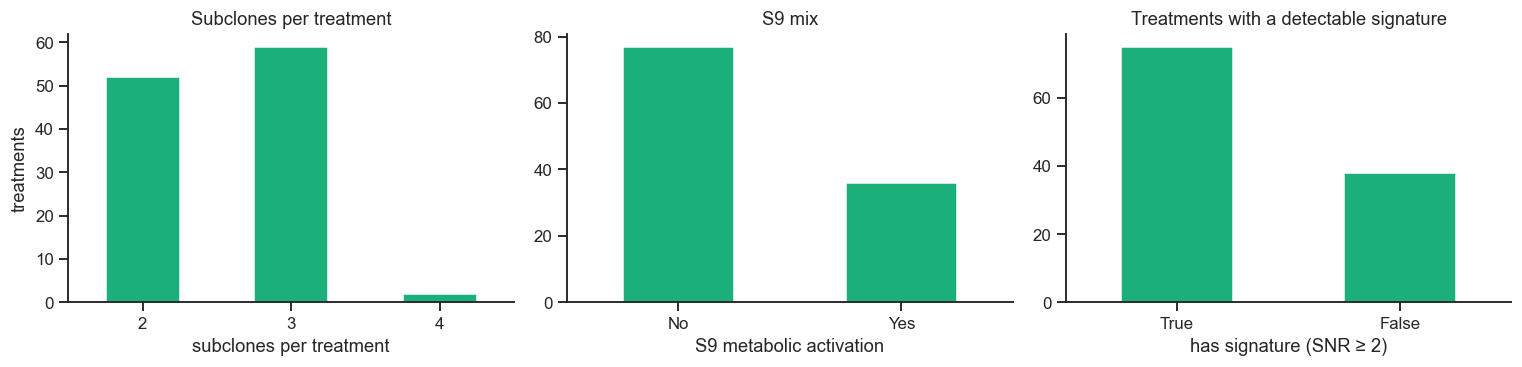

In [11]:
display(meta_kucab.describe(include="all").T[["count", "unique", "top", "mean", "min", "max"]])

per_group = (kucab_cols.groupby("group_label")
             .agg(parental=("Sample.Name", "nunique"), subclones=("Sample.Name", "size"),
                  compounds=("Compound", "nunique"))
             .sort_values("subclones", ascending=False))
display(per_group)

fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
meta_kucab.subclone_num.value_counts().sort_index().plot.bar(ax=axes[0], color=COHORT_COLORS["Kucab2019"])
axes[0].set(xlabel="subclones per treatment", ylabel="treatments", title="Subclones per treatment")
meta_kucab["S9.mix"].value_counts().plot.bar(ax=axes[1], color=COHORT_COLORS["Kucab2019"])
axes[1].set(xlabel="S9 metabolic activation", title="S9 mix")
meta_kucab.has_signature_SNRge2.value_counts().plot.bar(ax=axes[2], color=COHORT_COLORS["Kucab2019"])
axes[2].set(xlabel="has signature (SNR ≥ 2)", title="Treatments with a detectable signature")
for ax in axes:
    ax.tick_params(axis="x", rotation=0)
plt.tight_layout()

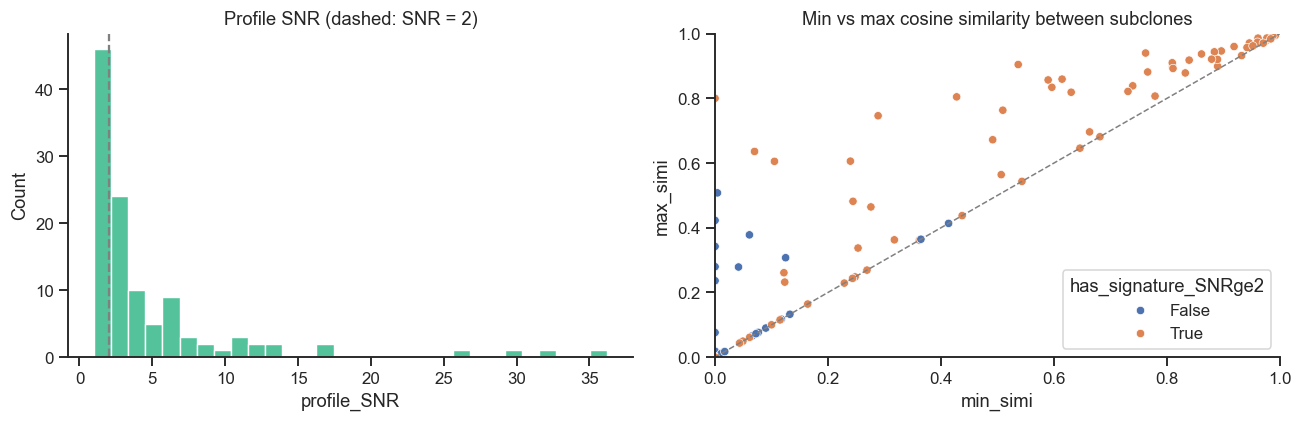

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(meta_kucab.profile_SNR, bins=30, ax=axes[0], color=COHORT_COLORS["Kucab2019"])
axes[0].axvline(2, ls="--", c="grey"); axes[0].set_title("Profile SNR (dashed: SNR = 2)")
sns.scatterplot(data=meta_kucab, x="min_simi", y="max_simi", hue="has_signature_SNRge2", ax=axes[1], s=30)
axes[1].plot([0, 1], [0, 1], c="grey", lw=1, ls="--")
axes[1].set(title="Min vs max cosine similarity between subclones", xlim=(0, 1), ylim=(0, 1))
plt.tight_layout()

## 3. Mutation burden

Burden matters for both the statistical model (Poisson/KL-NMF noise is dominated by low-count samples) and for OT (spectra are normalised to probability vectors, which hides how noisy a 20-mutation profile is).

In [13]:
burden = pd.concat([
    pd.DataFrame({"total_SBS": X.sum().values, "cohort": name, "sample": X.columns}) for name, X in cat.items()
], ignore_index=True)

summary = burden.groupby("cohort").total_SBS.describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]).loc[COHORTS]
for t in [10, 50, 100, 500]:
    summary[f"% < {t}"] = burden.groupby("cohort").total_SBS.apply(lambda s: 100 * (s < t).mean()).loc[COHORTS].round(1)
summary["zero-burden samples"] = burden.groupby("cohort").total_SBS.apply(lambda s: (s == 0).sum()).loc[COHORTS]
summary.round(1)

,count,mean,std,min,5%,25%,50%,75%,95%,max,% < 10,% < 50,% < 100,% < 500,zero-burden samples
cohort,,,,,,,,,,,,,,,
PCAWG_WGS,2780.0,17365.8,84673.0,21.0,429.0,2373.8,5259.5,11318.0,52123.2,2432617.0,0.0,0.2,1.1,5.5,0
TCGA_WES,9493.0,313.2,1324.8,1.0,12.0,38.0,83.0,197.0,1035.0,39688.0,3.5,32.9,56.0,89.5,0
Kucab2019,324.0,532.3,611.9,28.0,200.0,239.0,289.5,528.0,1778.2,4145.0,0.0,0.3,0.6,73.8,0


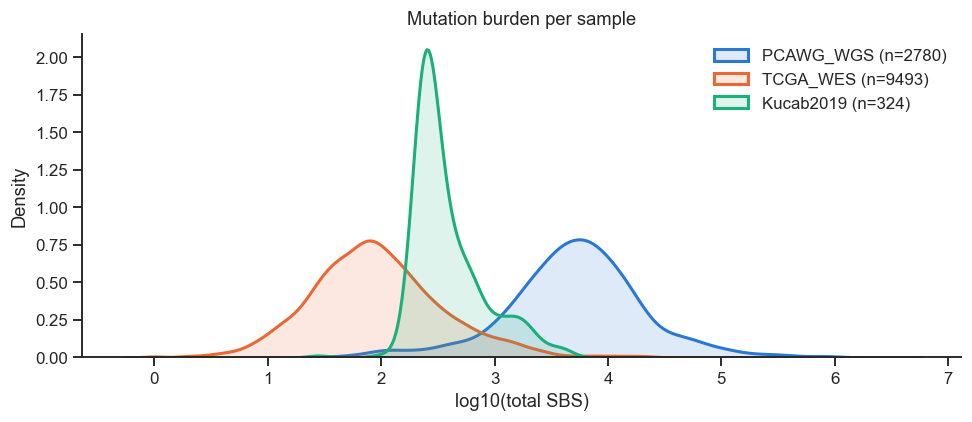

In [14]:
fig, ax = plt.subplots(figsize=(9, 4))
for name in COHORTS:
    vals = np.log10(burden.query("cohort == @name").total_SBS.clip(lower=1))
    sns.kdeplot(vals, ax=ax, label=f"{name} (n={len(vals)})", color=COHORT_COLORS[name], fill=True, alpha=0.15, lw=2)
ax.set(xlabel="log10(total SBS)", title="Mutation burden per sample")
ax.legend(frameon=False)
plt.tight_layout()

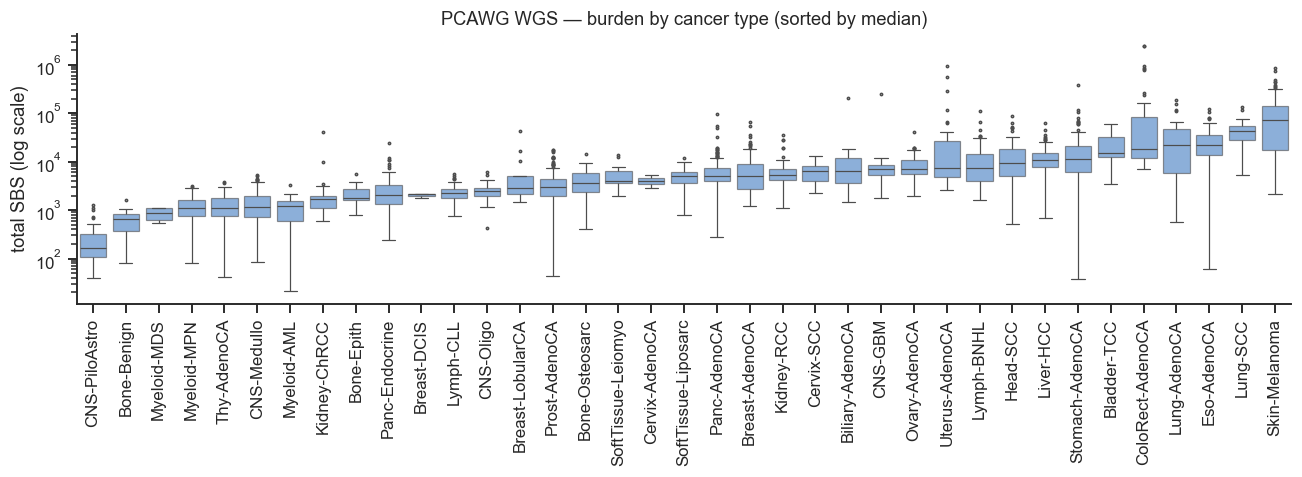

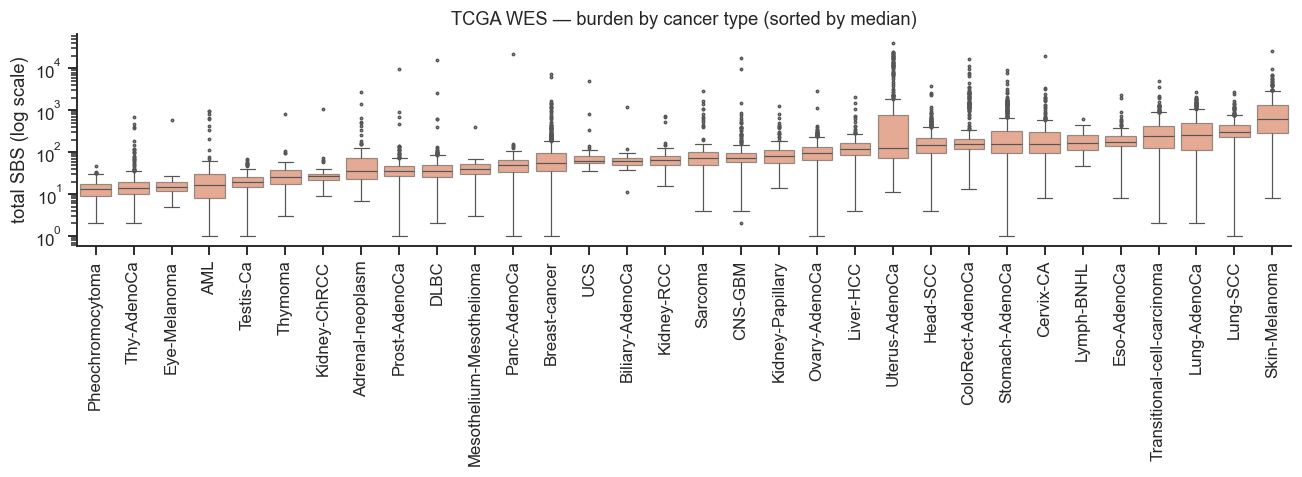

In [15]:
def burden_by_type(meta, title, color):
    order = meta.groupby("cancer_type").total_SBS.median().sort_values().index
    fig, ax = plt.subplots(figsize=(12, 4.5))
    sns.boxplot(data=meta, x="cancer_type", y="total_SBS", order=order, ax=ax,
                color=color, fliersize=1.5, linewidth=0.8, boxprops=dict(alpha=0.6))
    ax.set_yscale("log")
    ax.set(xlabel="", ylabel="total SBS (log scale)", title=title)
    ax.tick_params(axis="x", rotation=90)
    plt.tight_layout()

burden_by_type(meta_pcawg, "PCAWG WGS — burden by cancer type (sorted by median)", COHORT_COLORS["PCAWG_WGS"])
burden_by_type(meta_tcga, "TCGA WES — burden by cancer type (sorted by median)", COHORT_COLORS["TCGA_WES"])

,median SBS
Treatment,
DBADE (0.109 uM),3945.0
BPDE (0.125 uM),3178.0
6-Nitrochrysene (50 uM),2429.0
6-Nitrochrysene (50 uM) + S9,2341.5
SSR (1.25 J),1897.0
DMH (11.6 mM) + S9,1803.0
DBADE (0.0313 uM),1774.0
ENU (400 uM),1719.0
5-Methylchrysene (1.6 uM) + S9,1351.0


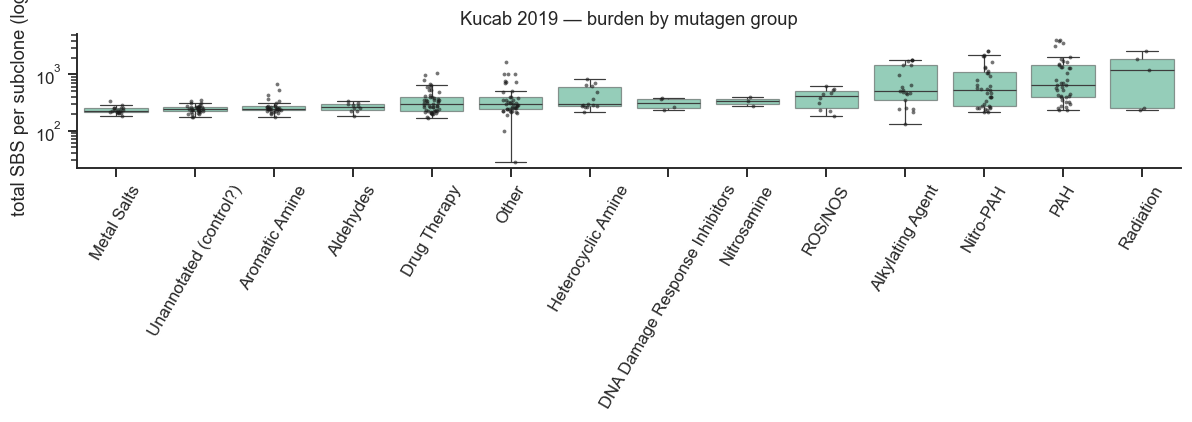

In [16]:
order = kucab_cols.groupby("group_label").total_SBS.median().sort_values().index
fig, ax = plt.subplots(figsize=(11, 4))
sns.boxplot(data=kucab_cols, x="group_label", y="total_SBS", order=order, ax=ax,
            color=COHORT_COLORS["Kucab2019"], fliersize=0, linewidth=0.8, boxprops=dict(alpha=0.5))
sns.stripplot(data=kucab_cols, x="group_label", y="total_SBS", order=order, ax=ax, color="k", size=2.5, alpha=0.6)
ax.set_yscale("log")
ax.set(xlabel="", ylabel="total SBS per subclone (log)", title="Kucab 2019 — burden by mutagen group")
ax.tick_params(axis="x", rotation=60)
plt.tight_layout()

display(kucab_cols.groupby("Treatment").total_SBS.median().sort_values(ascending=False).head(15).rename("median SBS").to_frame())

## 4. Sparsity

,count,mean,std,min,25%,50%,75%,max
cohort,,,,,,,,
PCAWG_WGS,2780.0,0.024,0.086,0.00,0.000,0.000,0.010,0.854
TCGA_WES,9493.0,0.557,0.235,0.00,0.385,0.583,0.750,0.990
Kucab2019,324.0,0.293,0.133,0.01,0.188,0.312,0.396,0.781


{'PCAWG_WGS': '2.4% of all matrix entries are zero', 'TCGA_WES': '55.7% of all matrix entries are zero', 'Kucab2019': '29.3% of all matrix entries are zero'}


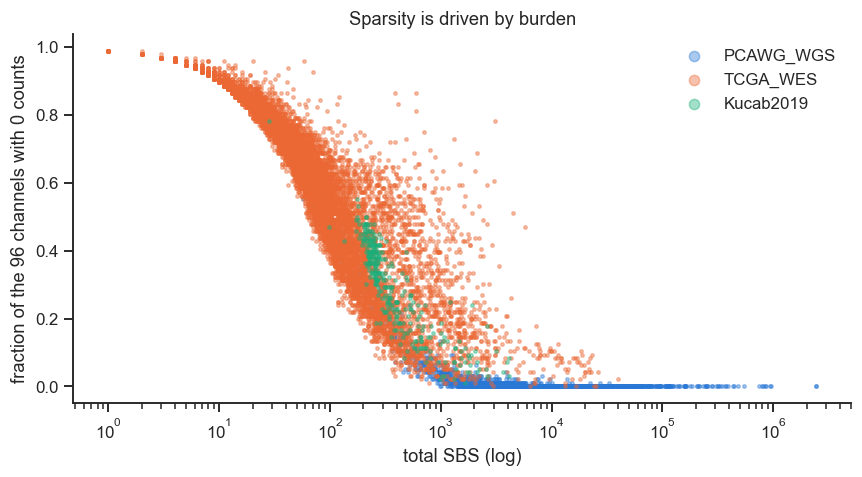

In [17]:
sparsity = pd.concat([
    pd.DataFrame({"frac_zero_channels": (X == 0).mean().values, "total_SBS": X.sum().values, "cohort": name})
    for name, X in cat.items()
], ignore_index=True)

display(sparsity.groupby("cohort").frac_zero_channels.describe().loc[COHORTS].round(3))
print({name: f"{(X.values == 0).mean():.1%} of all matrix entries are zero" for name, X in cat.items()})

fig, ax = plt.subplots(figsize=(8, 4.5))
for name in COHORTS:
    d = sparsity.query("cohort == @name")
    ax.scatter(d.total_SBS.clip(lower=1), d.frac_zero_channels, s=5, alpha=0.4, color=COHORT_COLORS[name], label=name)
ax.set_xscale("log")
ax.set(xlabel="total SBS (log)", ylabel="fraction of the 96 channels with 0 counts",
       title="Sparsity is driven by burden")
ax.legend(frameon=False, markerscale=3)
plt.tight_layout()

## 5. Mutational spectra

Profiles are normalised per sample to sum to 1 (probability vectors on the 96 channels — the objects OT compares). Cohort/group "mean profiles" are averages of normalised profiles, so each sample has equal weight regardless of burden.

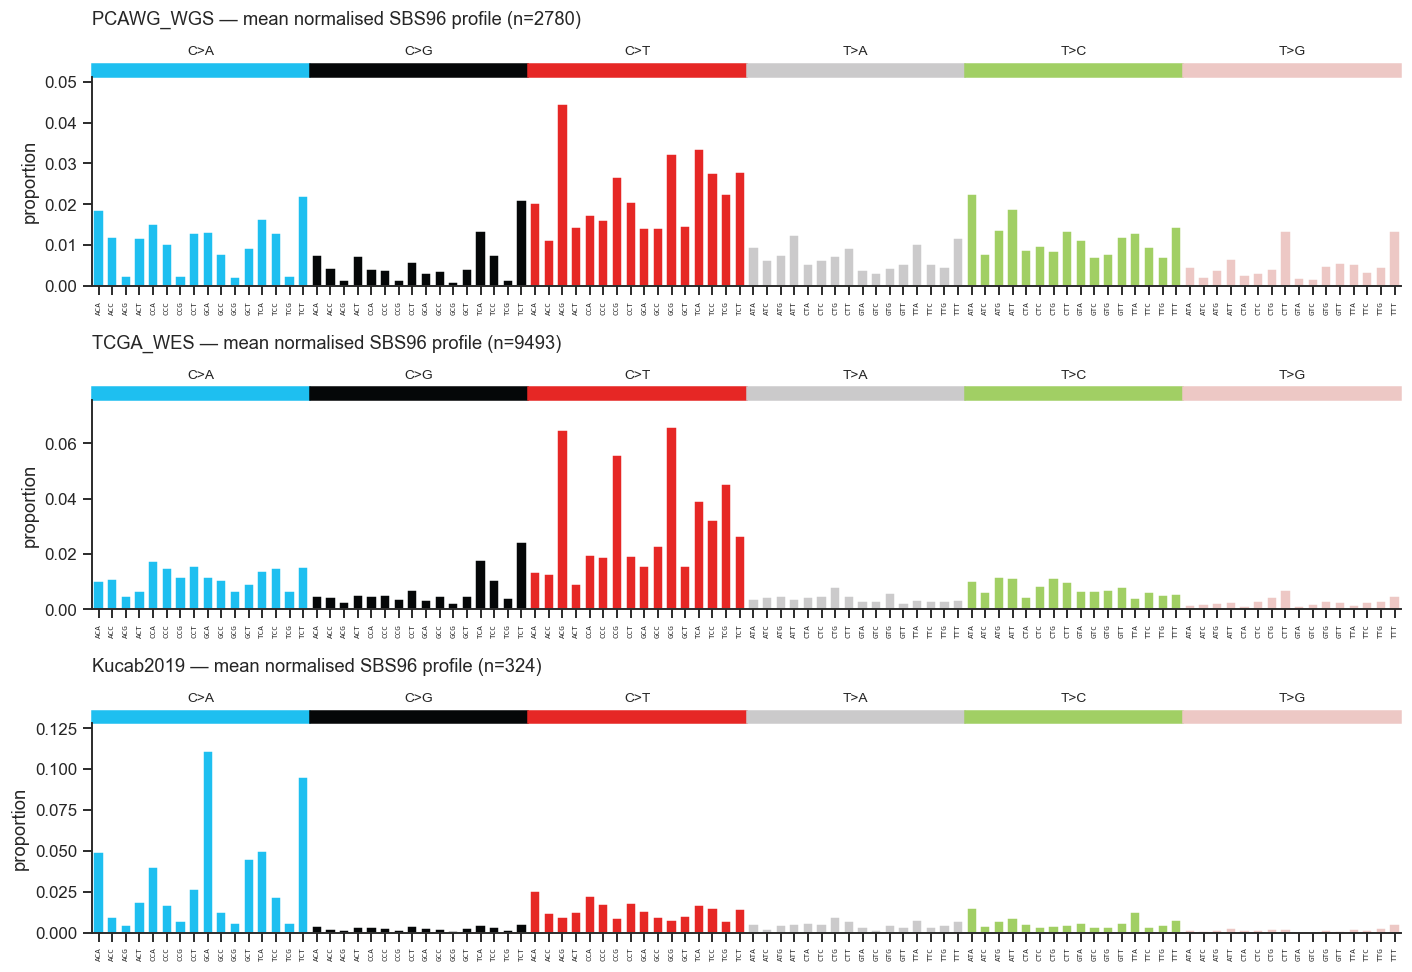

In [18]:
def normalize(X):
    s = X.sum()
    return X.loc[:, s > 0] / s[s > 0]

P = {k: normalize(X) for k, X in cat.items()}


def plot_sbs96(profile, ax, title="", ylabel="proportion"):
    x = np.arange(96)
    ax.bar(x, profile, color=[SUB_COLORS[s] for s in SUB_OF], width=0.75)
    ymax = profile.max() * 1.15
    for i, s in enumerate(SUBS):
        ax.add_patch(plt.Rectangle((16 * i - 0.5, ymax), 16, ymax * 0.06, color=SUB_COLORS[s], clip_on=False))
        ax.text(16 * i + 7.5, ymax * 1.09, s, ha="center", va="bottom", fontsize=9)
    ax.set_xlim(-0.5, 95.5); ax.set_ylim(0, ymax)
    ax.set_xticks(x)
    ax.set_xticklabels([c[0] + c[2] + c[-1] for c in CHANNELS], rotation=90, fontsize=5, family="monospace")
    ax.set_ylabel(ylabel)
    ax.set_title(title, loc="left", pad=34)


fig, axes = plt.subplots(3, 1, figsize=(13, 9))
for ax, name in zip(axes, COHORTS):
    plot_sbs96(P[name].mean(axis=1).values, ax, f"{name} — mean normalised SBS96 profile (n={P[name].shape[1]})")
plt.tight_layout()

### 5.1 Substitution-class composition

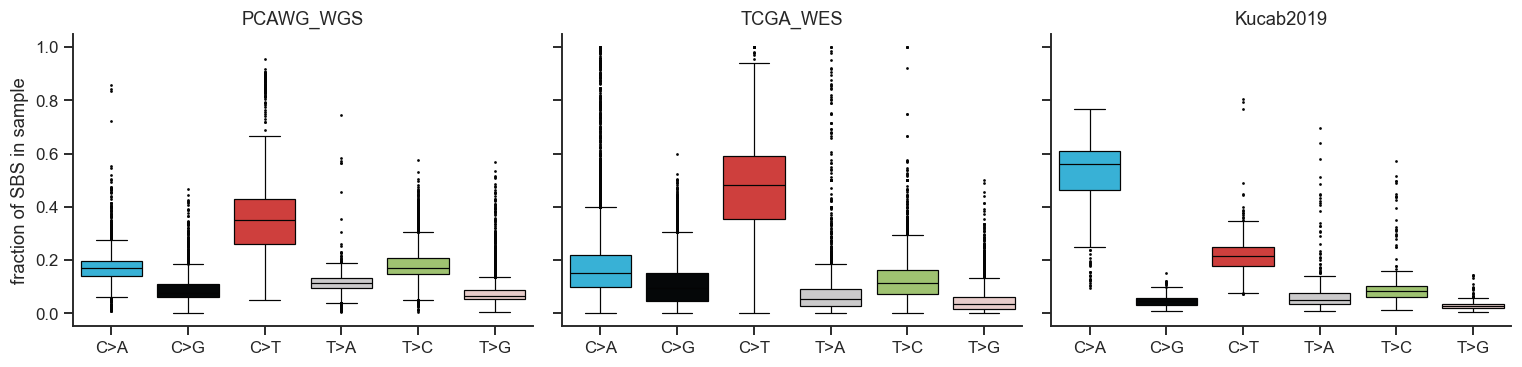

In [19]:
def sub_fractions(Pk):
    return Pk.groupby(SUB_OF).sum().T[SUBS]

fig, axes = plt.subplots(1, 3, figsize=(14, 3.5), sharey=True)
for ax, name in zip(axes, COHORTS):
    sns.boxplot(data=sub_fractions(P[name]), ax=ax, palette=SUB_COLORS, fliersize=0.8, linewidth=0.8)
    ax.set_title(name)
axes[0].set_ylabel("fraction of SBS in sample")
plt.tight_layout()

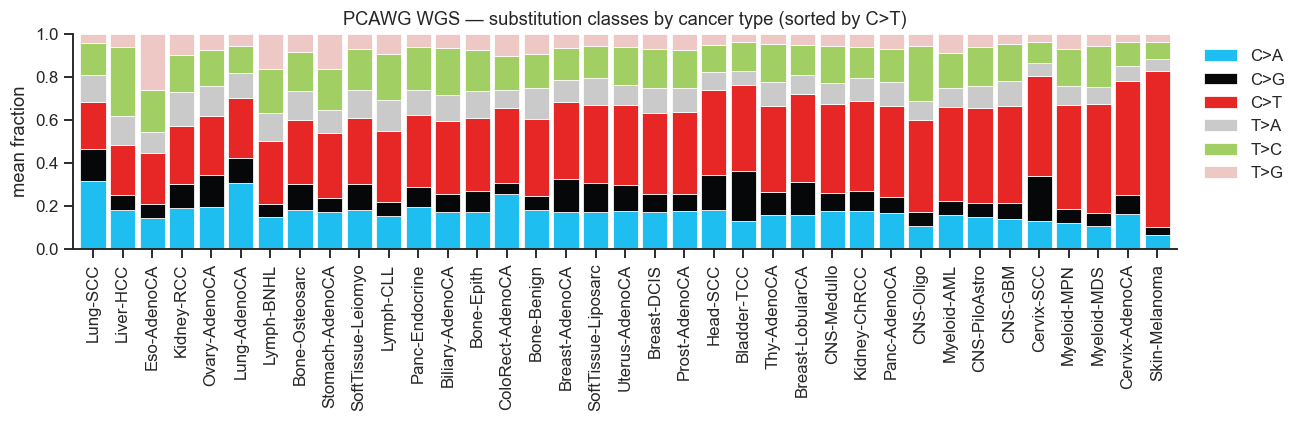

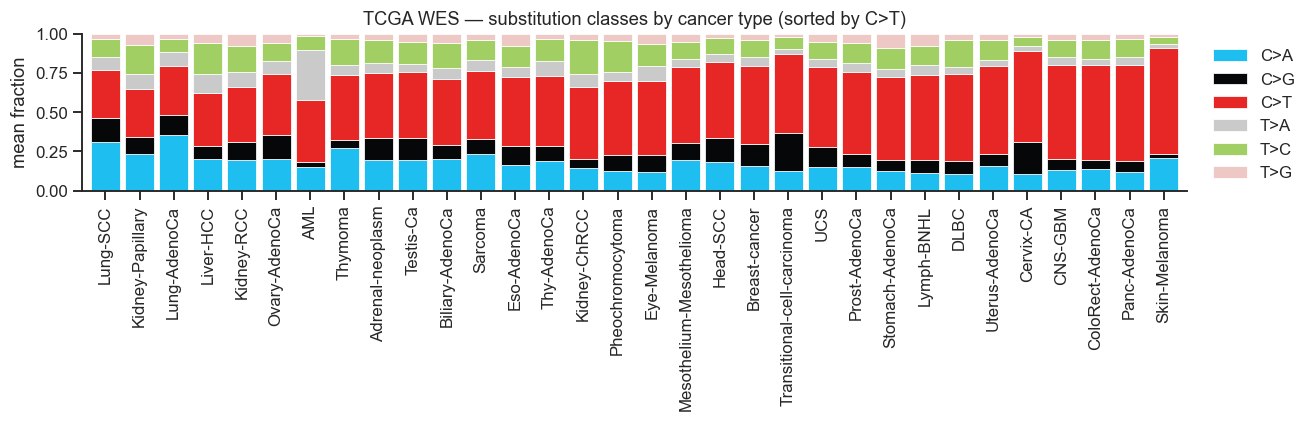

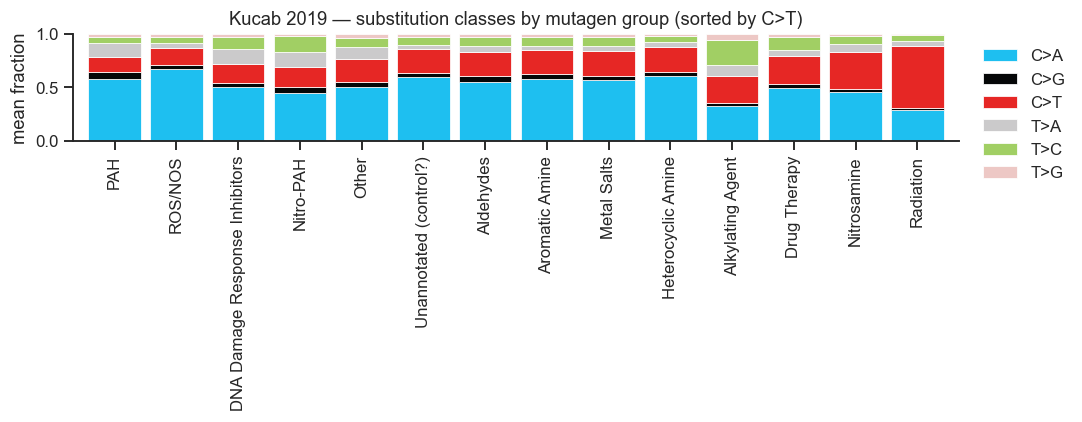

In [20]:
def stacked_sub_by(Pk, labels, title, figsize=(12, 4)):
    frac = sub_fractions(Pk).groupby(labels).mean()
    frac = frac.loc[frac["C>T"].sort_values().index]
    fig, ax = plt.subplots(figsize=figsize)
    frac.plot.bar(stacked=True, ax=ax, color=[SUB_COLORS[s] for s in SUBS], width=0.85, edgecolor="white", linewidth=0.5)
    ax.set(ylabel="mean fraction", xlabel="", title=title, ylim=(0, 1))
    ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left", frameon=False)
    plt.tight_layout()

stacked_sub_by(P["PCAWG_WGS"], P["PCAWG_WGS"].columns.str.split("::").str[0], "PCAWG WGS — substitution classes by cancer type (sorted by C>T)")
stacked_sub_by(P["TCGA_WES"], P["TCGA_WES"].columns.str.split("::").str[0], "TCGA WES — substitution classes by cancer type (sorted by C>T)")
stacked_sub_by(P["Kucab2019"], kucab_cols.loc[P["Kucab2019"].columns, "group_label"].values, "Kucab 2019 — substitution classes by mutagen group (sorted by C>T)", (10, 4))

### 5.2 Mean 96-channel profile per cancer type

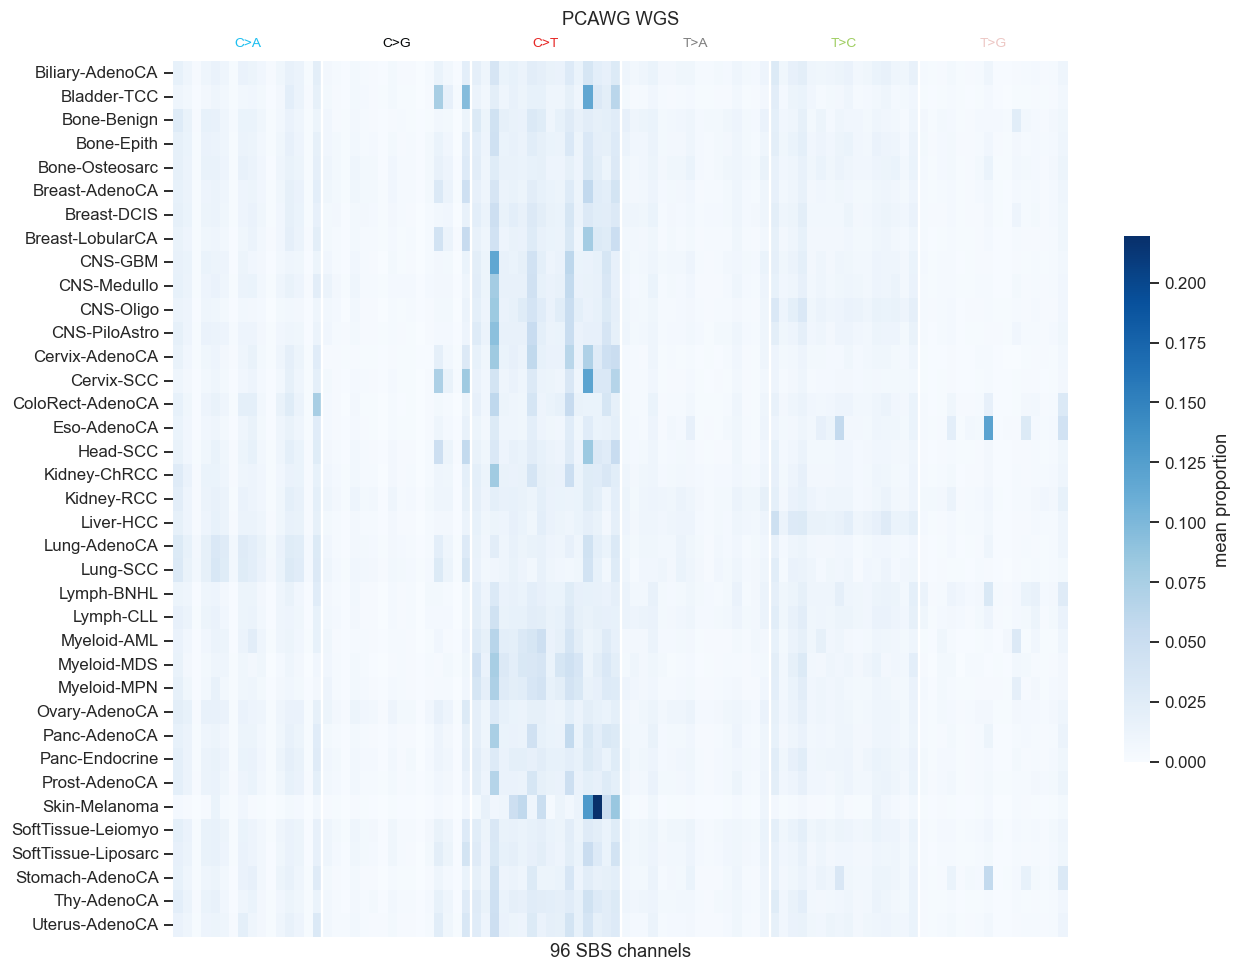

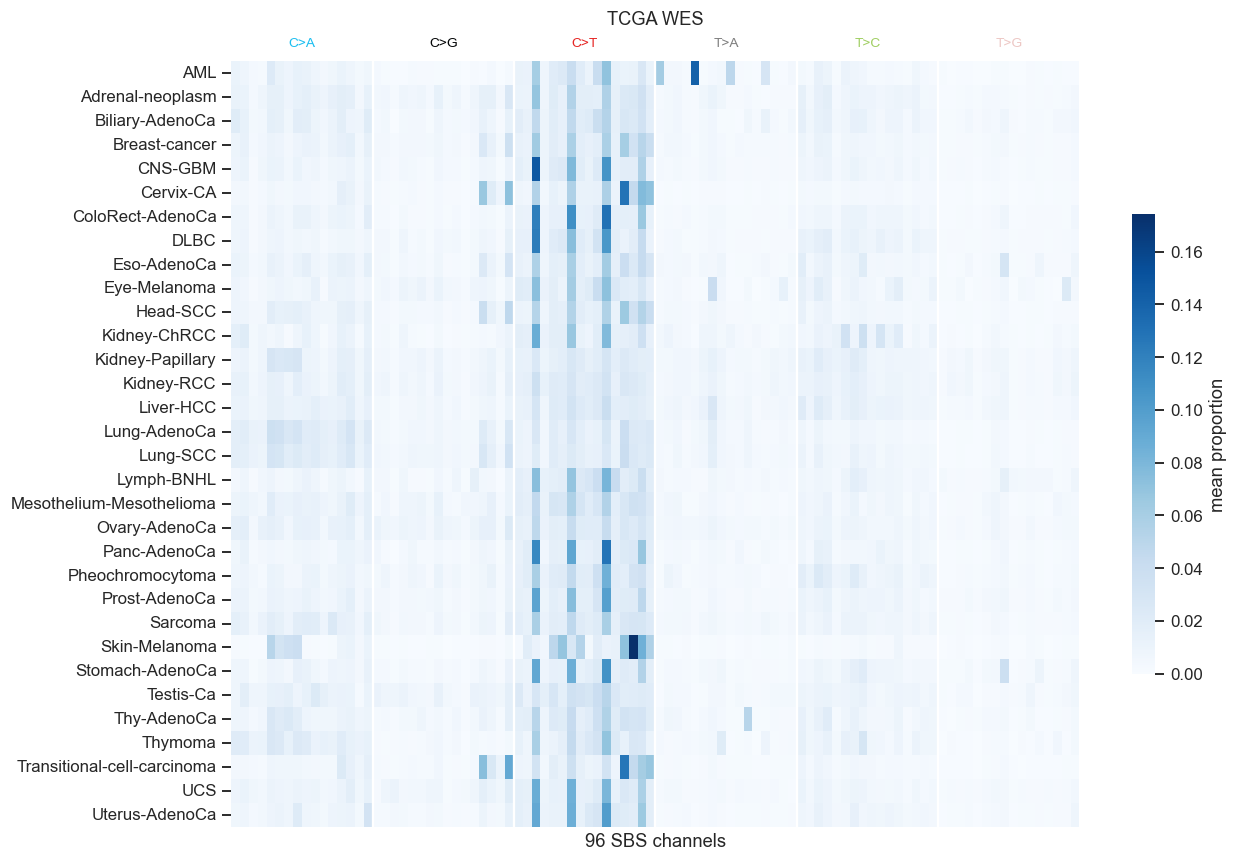

In [21]:
def profile_heatmap(Pk, labels, title, figsize):
    M = Pk.T.groupby(labels).mean()
    fig, ax = plt.subplots(figsize=figsize)
    sns.heatmap(M, cmap="Blues", ax=ax, cbar_kws={"label": "mean proportion", "shrink": 0.6},
                xticklabels=False, yticklabels=True)
    for i in range(1, 6):
        ax.axvline(16 * i, c="white", lw=1.5)
    for i, s in enumerate(SUBS):
        ax.text(16 * i + 8, -0.5, s, ha="center", va="bottom", fontsize=9, color=SUB_COLORS[s] if s != "T>A" else "grey")
    ax.set_title(title, pad=24)
    ax.set(xlabel="96 SBS channels", ylabel="")
    plt.tight_layout()

profile_heatmap(P["PCAWG_WGS"], P["PCAWG_WGS"].columns.str.split("::").str[0], "PCAWG WGS", (12, 9))
profile_heatmap(P["TCGA_WES"], P["TCGA_WES"].columns.str.split("::").str[0], "TCGA WES", (12, 8))

### 5.3 Kucab: strongest treatment spectra

Treatments with a detectable signature and the highest profile SNR, alongside the pooled unannotated (putative control) subclones.

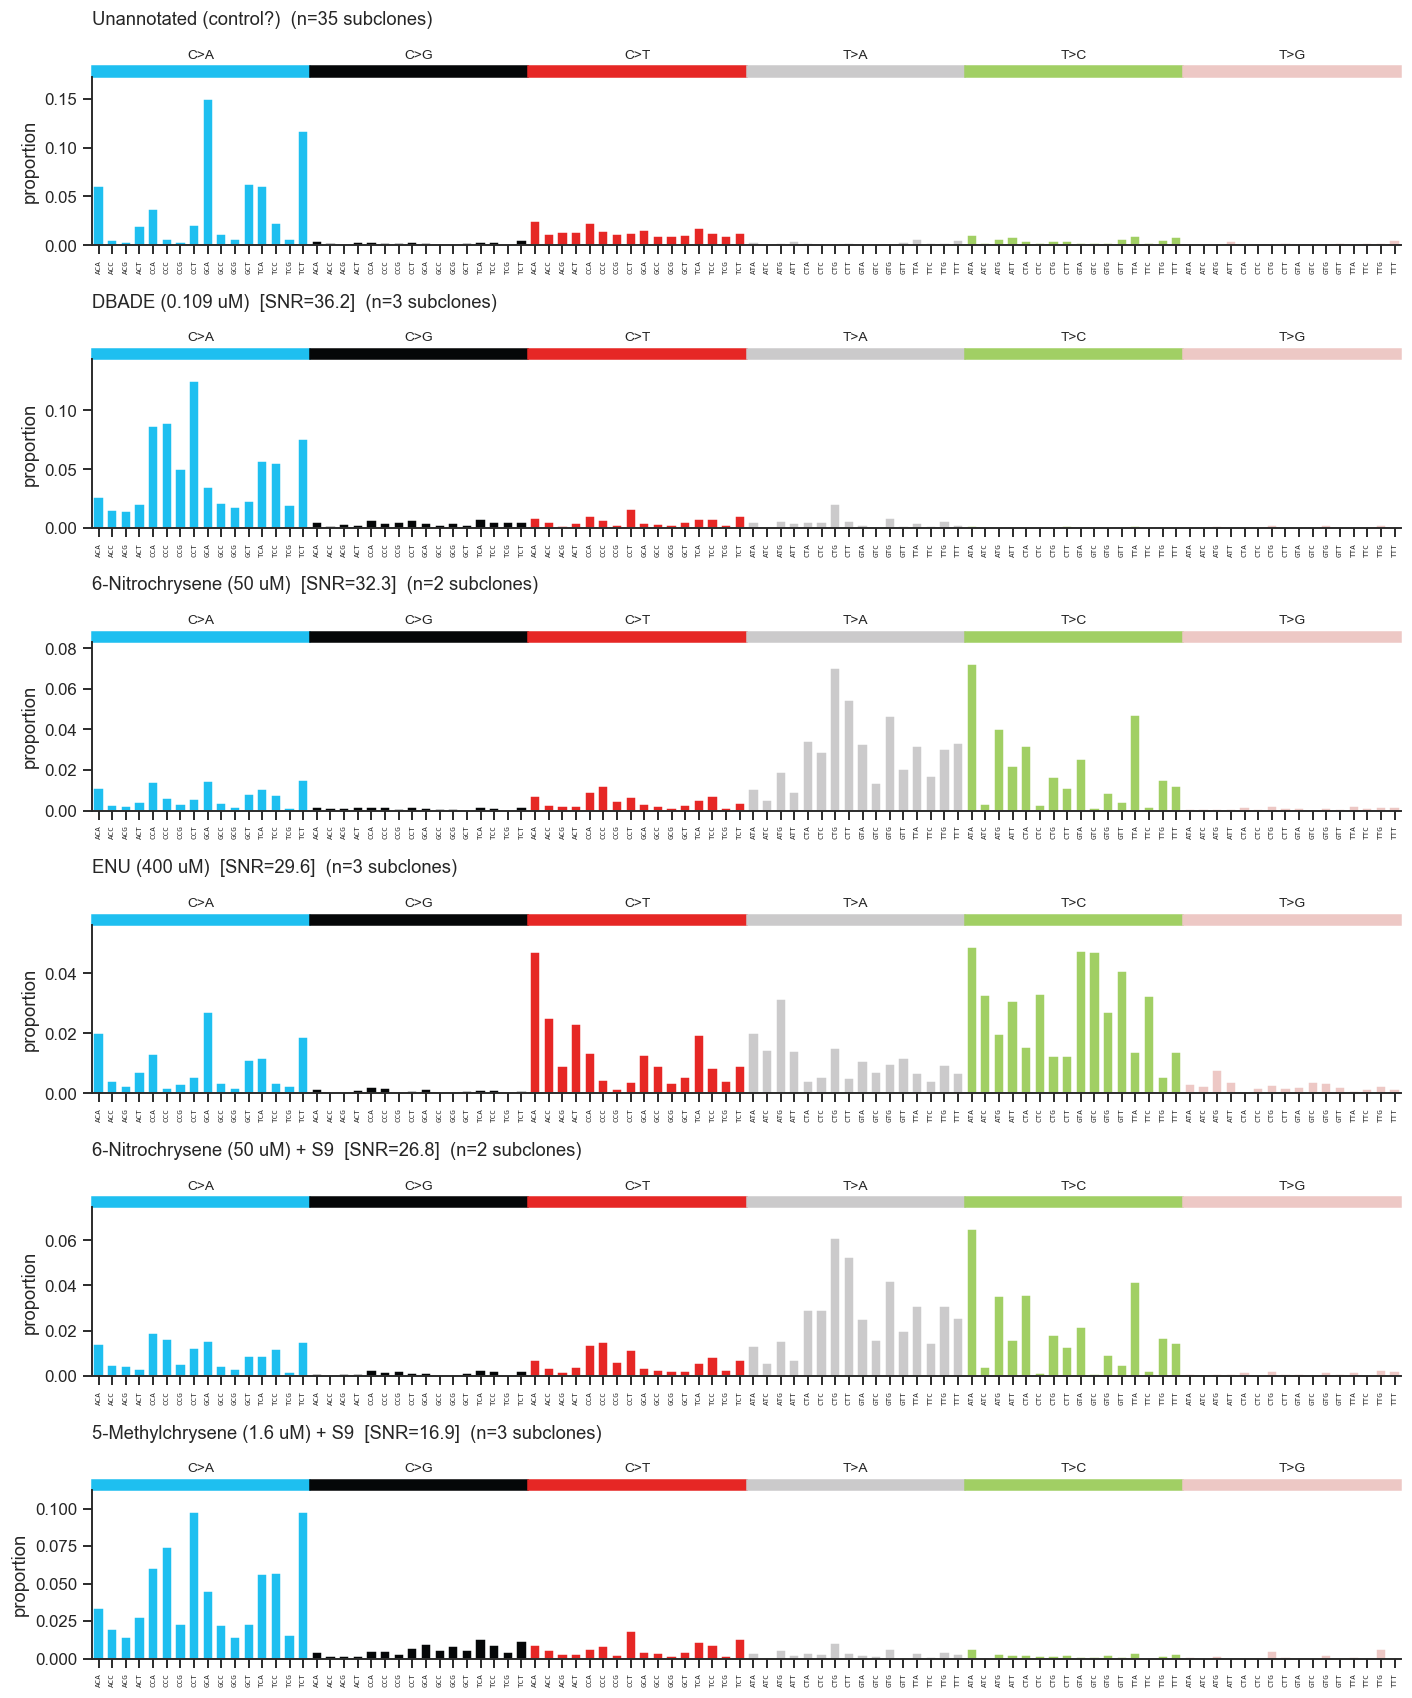

In [22]:
top = meta_kucab.query("has_signature_SNRge2").nlargest(5, "profile_SNR")
groups = [("Unannotated (control?)", kucab_cols.index[kucab_cols.Treatment == "Unannotated (control?)"])]
groups += [(f"{r.Treatment}  [SNR={r.profile_SNR:.1f}]", kucab_cols.index[kucab_cols["Sample.Name"] == r["Sample.Name"]])
           for _, r in top.iterrows()]

fig, axes = plt.subplots(len(groups), 1, figsize=(13, 2.6 * len(groups)))
for ax, (lab, cols) in zip(axes, groups):
    cols = cols.intersection(P["Kucab2019"].columns)
    plot_sbs96(P["Kucab2019"][cols].mean(axis=1).values, ax, f"{lab}  (n={len(cols)} subclones)")
plt.tight_layout()

## 6. Similarity structure

### 6.1 Between cohorts

Cosine similarity between cohort mean profiles. WES and WGS differ in trinucleotide opportunity (exomes are GC-rich, depleting e.g. NpCpG contexts relative to genomes), so some PCAWG–TCGA difference is expected even for identical processes.

,PCAWG_WGS,TCGA_WES,Kucab2019
PCAWG_WGS,1.000,0.909,0.601
TCGA_WES,0.909,1.000,0.463
Kucab2019,0.601,0.463,1.000


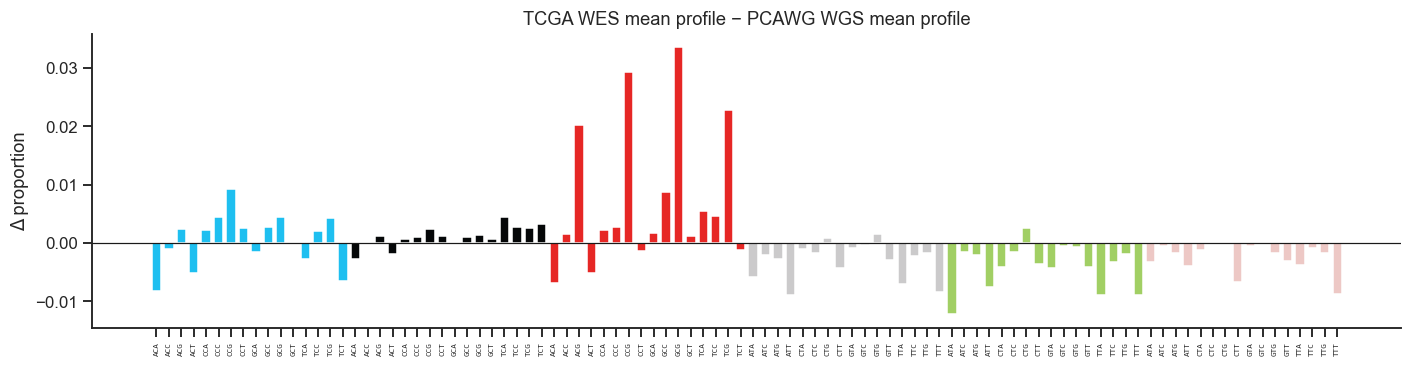

In [23]:
def cosine(A, B):
    A = A / np.linalg.norm(A, axis=0, keepdims=True)
    B = B / np.linalg.norm(B, axis=0, keepdims=True)
    return A.T @ B

means = pd.DataFrame({k: P[k].mean(axis=1) for k in COHORTS})
display(pd.DataFrame(cosine(means.values, means.values), index=COHORTS, columns=COHORTS).round(3))

fig, ax = plt.subplots(figsize=(13, 3.5))
diff = means["TCGA_WES"] - means["PCAWG_WGS"]
ax.bar(np.arange(96), diff, color=[SUB_COLORS[s] for s in SUB_OF], width=0.75)
ax.axhline(0, c="k", lw=0.8)
ax.set_xticks(np.arange(96))
ax.set_xticklabels([c[0] + c[2] + c[-1] for c in CHANNELS], rotation=90, fontsize=5, family="monospace")
ax.set(ylabel="Δ proportion", title="TCGA WES mean profile − PCAWG WGS mean profile")
plt.tight_layout()

### 6.2 Within cohorts: how heterogeneous are samples of the same cancer type / treatment?

,group,n,median pairwise cosine,cohort
18,Lung-AdenoCA,38,0.736664,PCAWG_WGS
33,Uterus-AdenoCA,51,0.783497,PCAWG_WGS
31,Stomach-AdenoCA,72,0.793106,PCAWG_WGS
10,CNS-PiloAstro,73,0.817098,PCAWG_WGS
12,ColoRect-AdenoCA,60,0.818401,PCAWG_WGS
6,DLBC,13,0.379379,TCGA_WES
1,Adrenal-neoplasm,14,0.523885,TCGA_WES
9,Kidney-Papillary,87,0.550359,TCGA_WES
17,Prost-AdenoCa,13,0.560348,TCGA_WES
18,Sarcoma,50,0.595562,TCGA_WES


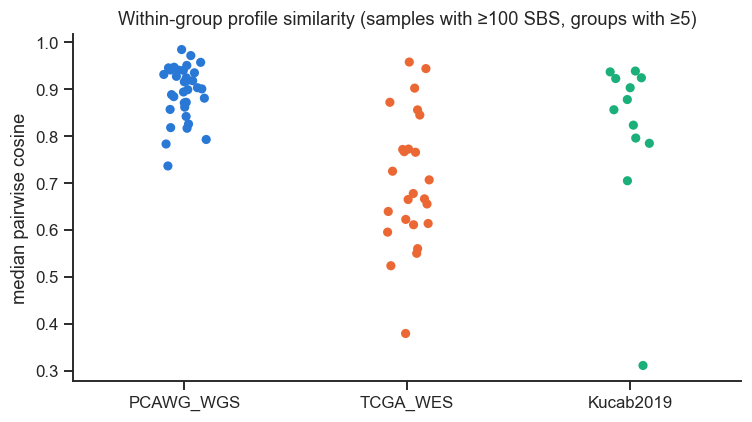

In [24]:
def within_group_cosine(Pk, labels, min_n=5):
    rows = []
    for g, idx in pd.Series(range(Pk.shape[1])).groupby(np.asarray(labels)):
        if len(idx) < min_n:
            continue
        S = cosine(Pk.values[:, idx], Pk.values[:, idx])
        rows.append({"group": g, "n": len(idx), "median pairwise cosine": np.median(S[np.triu_indices(len(idx), 1)])})
    return pd.DataFrame(rows).sort_values("median pairwise cosine")

MIN_SBS = 100  # restrict to samples with a reasonably estimated profile
keep = {k: cat[k].columns[cat[k].sum() >= MIN_SBS] for k in COHORTS}
wg = pd.concat([
    within_group_cosine(P["PCAWG_WGS"][keep["PCAWG_WGS"]], keep["PCAWG_WGS"].str.split("::").str[0]).assign(cohort="PCAWG_WGS"),
    within_group_cosine(P["TCGA_WES"][keep["TCGA_WES"]], keep["TCGA_WES"].str.split("::").str[0]).assign(cohort="TCGA_WES"),
    within_group_cosine(P["Kucab2019"][keep["Kucab2019"]], kucab_cols.loc[keep["Kucab2019"], "group_label"].values).assign(cohort="Kucab2019"),
])

fig, ax = plt.subplots(figsize=(7, 4))
sns.stripplot(data=wg, x="cohort", y="median pairwise cosine", hue="cohort", palette=COHORT_COLORS, order=COHORTS, ax=ax, size=6, legend=False)
ax.set(xlabel="", title=f"Within-group profile similarity (samples with ≥{MIN_SBS} SBS, groups with ≥5)")
plt.tight_layout()
wg.groupby("cohort").head(5)

### 6.3 Low-dimensional view

PCA on normalised profiles of samples with ≥100 SBS, pooled across cohorts. (Euclidean PCA on proportions is only a rough proxy for the OT geometry used later.)

Explained variance (first 10 PCs): [0.278 0.196 0.128 0.087 0.056 0.037 0.024 0.018 0.017 0.012]


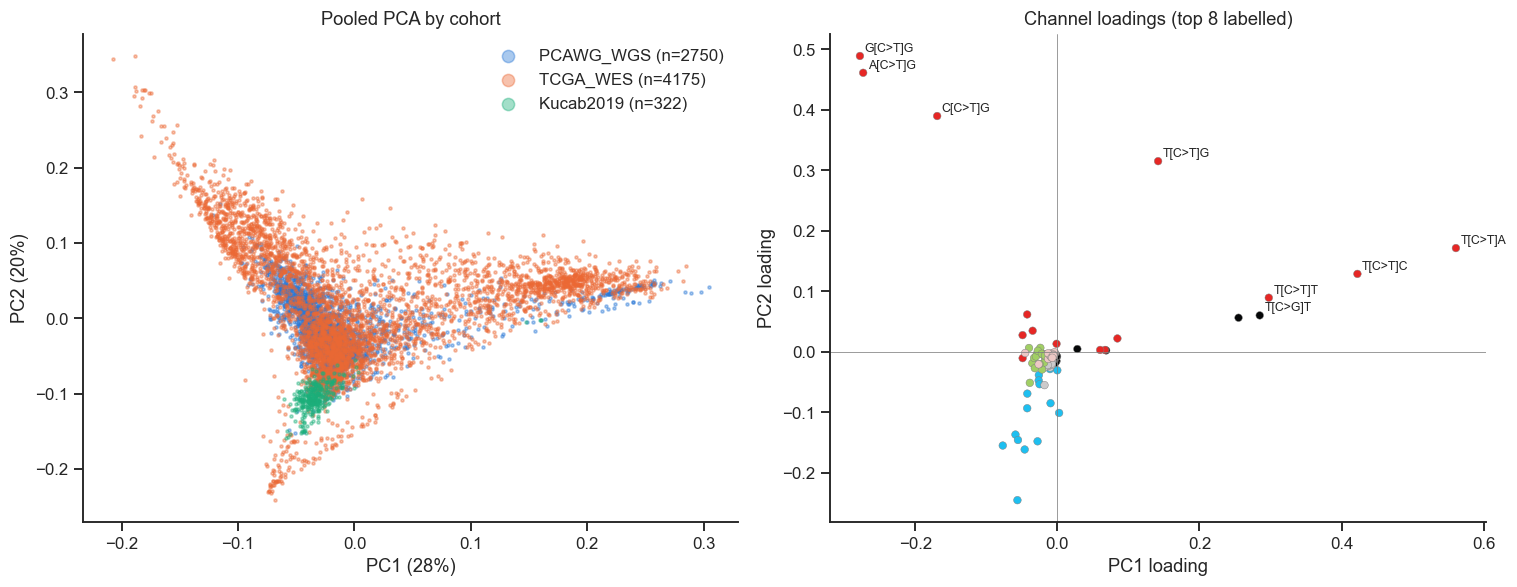

In [25]:
pooled = pd.concat([P[k][keep[k]] for k in COHORTS], axis=1)
pooled_cohort = np.concatenate([[k] * len(keep[k]) for k in COHORTS])

pca = PCA(n_components=10).fit(pooled.T.values)
Z = pca.transform(pooled.T.values)
print("Explained variance (first 10 PCs):", np.round(pca.explained_variance_ratio_, 3))

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for name in COHORTS:
    m = pooled_cohort == name
    axes[0].scatter(Z[m, 0], Z[m, 1], s=4, alpha=0.4, color=COHORT_COLORS[name], label=f"{name} (n={m.sum()})")
axes[0].set(xlabel=f"PC1 ({pca.explained_variance_ratio_[0]:.0%})", ylabel=f"PC2 ({pca.explained_variance_ratio_[1]:.0%})", title="Pooled PCA by cohort")
axes[0].legend(frameon=False, markerscale=4)

# Loadings of PC1 / PC2 coloured by substitution class
ax = axes[1]
ax.scatter(pca.components_[0], pca.components_[1], c=[SUB_COLORS[s] for s in SUB_OF], s=25, edgecolor="grey", linewidth=0.3)
for i in np.argsort(-(pca.components_[0] ** 2 + pca.components_[1] ** 2))[:8]:
    ax.annotate(CHANNELS[i], (pca.components_[0, i], pca.components_[1, i]), fontsize=8, xytext=(3, 3), textcoords="offset points")
ax.axhline(0, c="grey", lw=0.5); ax.axvline(0, c="grey", lw=0.5)
ax.set(xlabel="PC1 loading", ylabel="PC2 loading", title="Channel loadings (top 8 labelled)")
plt.tight_layout()

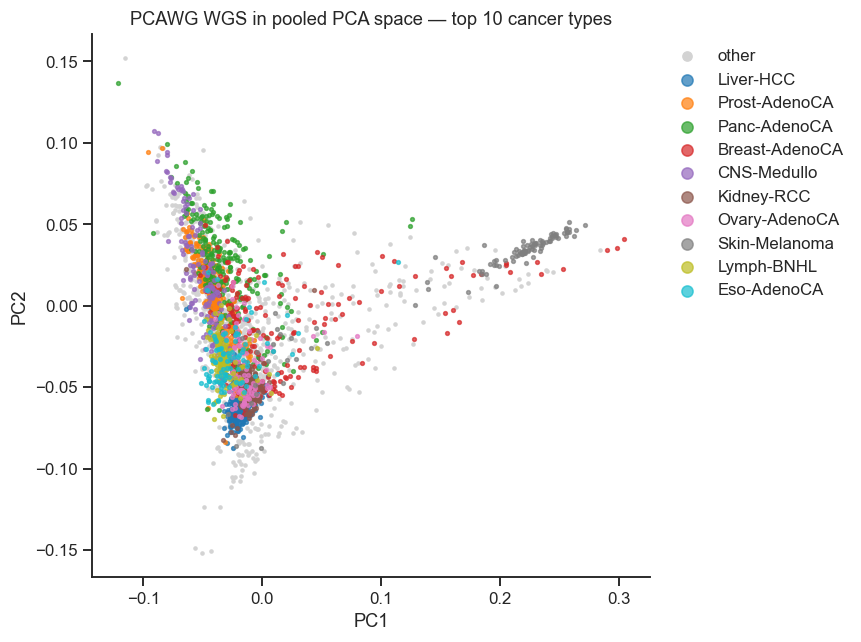

In [26]:
# Same embedding, PCAWG only, coloured by the 10 most frequent cancer types
labels = keep["PCAWG_WGS"].str.split("::").str[0]
top_types = labels.value_counts().index[:10]
m = pooled_cohort == "PCAWG_WGS"
Zp = Z[m]

fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(Zp[~labels.isin(top_types), 0], Zp[~labels.isin(top_types), 1], s=4, color="lightgrey", label="other")
pal = sns.color_palette("tab10", len(top_types))
for c, t in zip(pal, top_types):
    sel = labels == t
    ax.scatter(Zp[sel, 0], Zp[sel, 1], s=6, alpha=0.7, color=c, label=t)
ax.set(xlabel="PC1", ylabel="PC2", title="PCAWG WGS in pooled PCA space — top 10 cancer types")
ax.legend(frameon=False, markerscale=3, bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()

## 7. Summary

In [27]:
pd.DataFrame({
    name: {
        "samples": cat[name].shape[1],
        "groups (cancer types / mutagen groups)": (cat[name].columns.str.split("::").str[0].nunique() if name != "Kucab2019"
                                                   else kucab_cols.group_label.nunique()),
        "median SBS / sample": int(cat[name].sum().median()),
        "% samples < 100 SBS": round(100 * (cat[name].sum() < 100).mean(), 1),
        "% zero entries": round(100 * (cat[name].values == 0).mean(), 1),
        "samples ≥ 100 SBS": len(keep[name]),
    }
    for name in COHORTS
}).T

,samples,groups (cancer types / mutagen groups),median SBS / sample,% samples < 100 SBS,% zero entries,samples ≥ 100 SBS
PCAWG_WGS,2780.0,37.0,5259.0,1.1,2.4,2750.0
TCGA_WES,9493.0,32.0,83.0,56.0,55.7,4175.0
Kucab2019,324.0,14.0,289.0,0.6,29.3,322.0


**Notes for the NMF / OT modelling**

- All three catalogues share the same 96 channels; they are re-indexed to the canonical COSMIC order above — reuse `CHANNELS` so the ground-cost matrix lines up with the data.
- **TCGA WES is very low-burden and sparse** (see §3–4): many exomes carry only a handful of SBS, so their normalised profiles are mostly noise. Consider a burden threshold, burden-weighted loss, or pooling before fitting OT-NMF.
- **WES vs WGS opportunity**: TCGA and PCAWG profiles are not directly comparable without correcting for trinucleotide opportunity (§6.1).
- **PCAWG QC**: a small number of samples belong to gray-listed/excluded donors, and some donors contribute multiple specimens (§2.1); decide whether to drop/deduplicate.
- **Kucab**: 15 parental samples have no metadata (putative untreated controls; verify). Many treatments have no detectable signature (SNR < 2); the high-SNR ones (§5.3) are the natural ground-truth signatures for validating recovered components.